# NIFTY 50 Explorer: when markets crash, who falls together?

**Central question:** *In the sell-offs of the last decade, which NIFTY 50 stocks and sectors protected capital, which fell hardest, and did diversification actually work when it mattered?*

This notebook lets you pick any stocks and sectors and look at the same market through five lenses:

| Lens | What it answers |
|---|---|
| **Indexed returns** | Rs 100 invested at the start: where did it end up? |
| **Drawdowns** | How deep was each fall from the previous peak, and how long did it last? |
| **Volatility** | How violent were the daily moves, and when did risk spike? |
| **Correlation heatmap** | Do these names move together, and does that change in a crash? |
| **Crash comparison** | Line up the biggest market falls side by side and see who held up |

**Data:** daily prices for the 50 current NIFTY 50 constituents, 10 Oct 2012 to 7 Oct 2022 (2,463 trading days), from the public GitHub dataset `Ram9219/NIFTY-50-Stock-Market-Data-2000---2022-`. Prices are dividend- and split-adjusted closes. The data is **embedded in this notebook**, so it runs offline.

**Important caveats**
- The index itself is not in the dataset. The "market" line throughout is an **equal-weight portfolio of the constituents** available on each day, a proxy that behaves differently from the cap-weighted NIFTY 50 (it gives small names more say).
- The stock list is **today's** constituents looked at backwards (survivorship bias): stocks that dropped out of the index earlier are absent, which flatters historical returns.
- The data ends in October 2022, so recent events are not covered.

**How to use it:** run all cells, then use the dashboard in the last section (needs `ipywidgets`, standard in Jupyter and Colab). Every chart function can also be called directly with your own selections.

In [1]:
import warnings, zlib, base64, json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

# --- Visual system: validated categorical palette (colour-blind-checked, fixed order) ---
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKET_C = "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 100,
})
MAX_PICK = len(SERIES)   # at most 8 lines per chart so colours are never recycled

## 1. Load the data

The prices are stored compactly inside the next cell (compressed, ~1 MB) so the notebook needs no internet. It contains adjusted close, raw close and volume for all 50 stocks.

In [2]:
BLOB = "..."

In [3]:
def decode(blob):
    p = zlib.decompress(base64.b64decode(blob))
    hl = int.from_bytes(p[:4], "little"); meta = json.loads(p[4:4 + hl])
    T, N, F = meta["T"], meta["N"], len(meta["fields"]); off = 4 + hl
    dates = pd.to_datetime(np.frombuffer(p[off:off + 4 * T], dtype="<i4").astype("datetime64[D]"))
    body = np.frombuffer(p[off + 4 * T:], dtype=np.uint8).reshape(4, -1).T
    arr = np.ascontiguousarray(body).view("<f4").reshape(F, T, N)
    return {f: pd.DataFrame(arr[i].astype("float64"), index=dates, columns=meta["symbols"]) for i, f in enumerate(meta["fields"])}

raw = decode(BLOB)
adj, close, volume = raw["adj"], raw["close"], raw["volume"]
print(f"{adj.shape[1]} stocks x {adj.shape[0]} trading days: {adj.index[0].date()} to {adj.index[-1].date()}")
print("Stocks with a shorter history:", {c: str(adj[c].first_valid_index().date()) for c in adj if adj[c].first_valid_index() != adj.index[0]})

50 stocks x 2463 trading days: 2012-10-10 to 2022-10-07
Stocks with a shorter history: {'HDFCLIFE': '2017-11-17', 'SBILIFE': '2017-10-03'}


## 2. Data quality: three problems found and handled

I checked every series for gaps, impossible prices and suspicious jumps before trusting any number. Three things needed attention:

1. **HDFC (the lender) has ~500 frozen days** (Dec 2013 to Dec 2015): a flat price of 818.20 with zero volume, then a sudden +50% jump when real data resumes. That is a data gap, not a market move, so those days are blanked out.
2. **Tata Steel's adjusted close is wrong before 16 Jun 2022**: it is about half the raw close because the adjustment factor was applied inconsistently, which would fabricate a +100% single-day jump. It is rescaled so history is consistent.
3. **Adani Enterprises, 3 Jun 2015**: closes -38.7% in one day with a bad open tick (312 against a 97 prior close). This looks like a corporate action not reflected in the data, but I could not verify it from here, so it is **kept and flagged**.

In [4]:
# 1) Blank out frozen periods: runs of 5+ consecutive zero-volume days (isolated zero-volume days
#    are ordinary non-trading sessions and are left alone)
zero = volume.eq(0)
stale = zero.apply(lambda c: c & (c.groupby((~c).cumsum()).transform("sum") >= 5))
px = adj.mask(stale)
n_bad = stale.sum()
print("Frozen days blanked out:", n_bad[n_bad > 0].to_dict())
for c in n_bad[n_bad > 0].index:
    d = stale.index[stale[c]]
    print(f"  {c}: {d.min().date()} to {d.max().date()}")

# 2) Repair broken adjustment factors: a >30% one-day change in adj/close is not a dividend
ratio = adj / close
step = ratio.pct_change(fill_method=None)
for sym in px.columns:
    bad = step.index[step[sym].abs() > 0.30]
    for d in bad:
        factor = 1 + step.loc[d, sym]
        px.loc[: d - pd.Timedelta(days=1), sym] *= factor
        print(f"Rescaled {sym} before {d.date()} by x{factor:.3f}")

# 3) Remaining extreme days, for transparency
r_raw = px.pct_change(fill_method=None)
ext = r_raw.stack()
ext = ext[ext.abs() > 0.30]
print("Daily moves beyond +/-30% after cleaning:")
display(ext.rename("return").to_frame().round(3))

Frozen days blanked out: {'HDFC': 499}
  HDFC: 2013-12-12 to 2015-12-24
Rescaled TATASTEEL before 2022-06-16 by x2.134
Daily moves beyond +/-30% after cleaning:


,,return
2015-06-03,ADANIENT,-0.387
2020-03-26,INDUSINDBK,0.447


## 3. Sectors and the market proxy

Each stock is mapped to one of ten sectors (a simple editorial grouping, close to NSE sector indices). Sector lines are **equal-weight** portfolios of their members. The market line is an equal-weight portfolio of all stocks trading that day.

In [5]:
SECTORS = {
    "Banks": ["AXISBANK", "HDFCBANK", "ICICIBANK", "INDUSINDBK", "KOTAKBANK", "SBIN"],
    "Financial Services": ["BAJFINANCE", "BAJAJFINSV", "HDFC", "HDFCLIFE", "SBILIFE"],
    "IT": ["HCLTECH", "INFY", "TCS", "TECHM", "WIPRO"],
    "Oil & Gas": ["BPCL", "ONGC", "RELIANCE"],
    "Auto": ["BAJAJ-AUTO", "EICHERMOT", "HEROMOTOCO", "M_and_M", "MARUTI", "TATAMOTORS"],
    "Consumer": ["ASIANPAINT", "BRITANNIA", "HINDUNILVR", "ITC", "NESTLEIND", "TATACONSUM", "TITAN"],
    "Metals & Mining": ["COALINDIA", "HINDALCO", "JSWSTEEL", "TATASTEEL"],
    "Pharma & Health": ["APOLLOHOSP", "CIPLA", "DIVISLAB", "DRREDDY", "SUNPHARMA"],
    "Industrials & Materials": ["ADANIENT", "ADANIPORTS", "GRASIM", "LT", "ULTRACEMCO", "UPL"],
    "Telecom & Power": ["BHARTIARTL", "NTPC", "POWERGRID"],
}
STOCK_SECTOR = {s: sec for sec, ss in SECTORS.items() for s in ss}
assert sorted(STOCK_SECTOR) == sorted(px.columns), "every stock must be mapped exactly once"
SYMBOLS = sorted(px.columns)

ret = px.pct_change(fill_method=None)            # daily simple returns (NaN across data gaps)
mkt_ret = ret.mean(axis=1, skipna=True).fillna(0)
MKT = (1 + mkt_ret).cumprod() * 100               # equal-weight market proxy, base 100
MKT.name = "Market (equal-weight)"

print({k: len(v) for k, v in SECTORS.items()})
print(f"Equal-weight market proxy: 100 -> {MKT.iloc[-1]:.0f} over the sample")

{'Banks': 6, 'Financial Services': 5, 'IT': 5, 'Oil & Gas': 3, 'Auto': 6, 'Consumer': 7, 'Metals & Mining': 4, 'Pharma & Health': 5, 'Industrials & Materials': 6, 'Telecom & Power': 3}
Equal-weight market proxy: 100 -> 721 over the sample


## 4. Core metrics and chart helpers

Everything below works on either **stocks** or **sectors** (`kind="stock"` or `kind="sector"`). A chart shows at most 8 lines so that colours are never recycled.

In [6]:
TDAYS = 252

def level(kind, items, start=None, end=None):
    # Price-like level series for stocks, or equal-weight sector portfolios.
    if kind == "sector":
        L = pd.DataFrame({s: (1 + ret[SECTORS[s]].mean(axis=1, skipna=True).fillna(0)).cumprod() for s in items})
    else:
        L = px[list(items)].copy()
    return L.loc[start:end]

def returns_of(kind, items, start=None, end=None):
    if kind == "sector":
        R = pd.DataFrame({s: ret[SECTORS[s]].mean(axis=1, skipna=True) for s in items})
    else:
        R = ret[list(items)]
    return R.loc[start:end]

def rebase(L, base=100.0):
    first = L.apply(lambda c: c.loc[c.first_valid_index()] if c.first_valid_index() is not None else np.nan)
    return L / first * base

def drawdown(L):
    return L / L.cummax() - 1

def stats_table(kind, items, start=None, end=None):
    L = level(kind, items, start, end)
    R = returns_of(kind, items, start, end)
    M = MKT.loc[start:end]
    rows = {}
    for c in L.columns:
        s = L[c].dropna()
        yrs = max((s.index[-1] - s.index[0]).days / 365.25, 1e-9)
        tot = s.iloc[-1] / s.iloc[0] - 1
        vol = R[c].std() * np.sqrt(TDAYS)
        dd = drawdown(s)
        rows[c] = {"Total return %": tot * 100, "CAGR %": ((1 + tot) ** (1 / yrs) - 1) * 100,
                   "Ann. volatility %": vol * 100, "Max drawdown %": dd.min() * 100,
                   "Worst day %": R[c].min() * 100, "Return / vol": ((1 + tot) ** (1 / yrs) - 1) / vol if vol else np.nan}
    mr = mkt_ret.loc[start:end]
    tot = M.iloc[-1] / M.iloc[0] - 1; yrs = (M.index[-1] - M.index[0]).days / 365.25
    rows["Market (equal-weight)"] = {"Total return %": tot * 100, "CAGR %": ((1 + tot) ** (1 / yrs) - 1) * 100,
                                     "Ann. volatility %": mr.std() * np.sqrt(TDAYS) * 100,
                                     "Max drawdown %": drawdown(M).min() * 100, "Worst day %": mr.min() * 100,
                                     "Return / vol": ((1 + tot) ** (1 / yrs) - 1) / (mr.std() * np.sqrt(TDAYS))}
    return pd.DataFrame(rows).T.round(2)

def _cap(items):
    items = list(items)
    if len(items) > MAX_PICK:
        print(f"Showing the first {MAX_PICK} of {len(items)} selections (a chart never recycles colours).")
        items = items[:MAX_PICK]
    return items

def _style(ax, title, sub=None, ylabel=None):
    ax.set_title(title, loc="left", pad=22 if sub else 8)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")
    if ylabel: ax.set_ylabel(ylabel)

def _end_labels(ax, series_list, colors, fmt="{:.0f}"):
    # direct labels at the right edge, nudged apart so they never collide
    ys = [(s.dropna().iloc[-1] if len(s.dropna()) else np.nan) for s in series_list]
    order = np.argsort([y if np.isfinite(y) else -1e18 for y in ys])
    lo, hi = ax.get_ylim(); gap = (hi - lo) * 0.035; last = -1e18; pos = {}
    for i in order:
        if not np.isfinite(ys[i]): continue
        p = max(ys[i], last + gap); pos[i] = p; last = p
    x1 = ax.get_xlim()[1]
    for i, p in pos.items():
        ax.annotate(f"{series_list[i].name}  {fmt.format(ys[i])}", xy=(x1, p), xytext=(6, 0), textcoords="offset points",
                    color=INK, fontsize=8.5, va="center", annotation_clip=False)

## 5. Indexed returns

Every line starts at 100 on the first day of the chosen window, so a stock that cost Rs 40 and one that cost Rs 4,000 are directly comparable. The dashed grey line is the equal-weight market proxy.

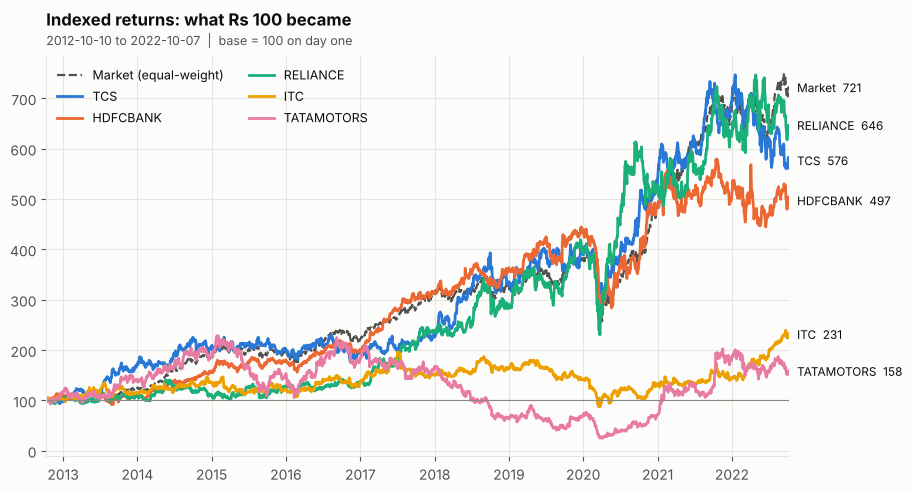

,Total return %,CAGR %,Ann. volatility %,Max drawdown %,Worst day %,Return / vol
TCS,476.04,19.16,24.69,-27.21,-9.41,0.78
HDFCBANK,396.50,17.40,23.72,-41.05,-12.61,0.73
RELIANCE,546.06,20.53,28.59,-45.09,-13.15,0.72
ITC,130.89,8.74,26.10,-55.35,-12.81,0.33
TATAMOTORS,57.55,4.66,42.77,-89.08,-17.58,0.11
Market (equal-weight),621.02,21.86,17.08,-38.33,-12.93,1.28


In [7]:
def plot_returns(kind="stock", items=("TCS", "HDFCBANK", "RELIANCE", "ITC"), start=None, end=None, log=False):
    items = _cap(items)
    L = rebase(level(kind, items, start, end))
    M = rebase(MKT.loc[start:end].to_frame()).iloc[:, 0]; M.name = "Market"
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.plot(M.index, M, color=MARKET_C, lw=1.6, ls="--", label="Market (equal-weight)")
    for i, c in enumerate(L.columns):
        ax.plot(L.index, L[c], color=SERIES[i], label=c)
    if log: ax.set_yscale("log")
    ax.axhline(100, color=MUTED, lw=0.8)
    ax.set_xlim(L.index[0], L.index[-1]); fig.subplots_adjust(right=0.80)
    _style(ax, "Indexed returns: what Rs 100 became", f"{L.index[0].date()} to {L.index[-1].date()}  |  base = 100 on day one" + ("  |  log scale" if log else ""))
    _end_labels(ax, [M] + [L[c] for c in L.columns], [MARKET_C] + SERIES[:len(L.columns)])
    ax.legend(loc="upper left", ncol=2, fontsize=9)
    plt.show()
    display(stats_table(kind, items, start, end))

plot_returns("stock", ["TCS", "HDFCBANK", "RELIANCE", "ITC", "TATAMOTORS"])

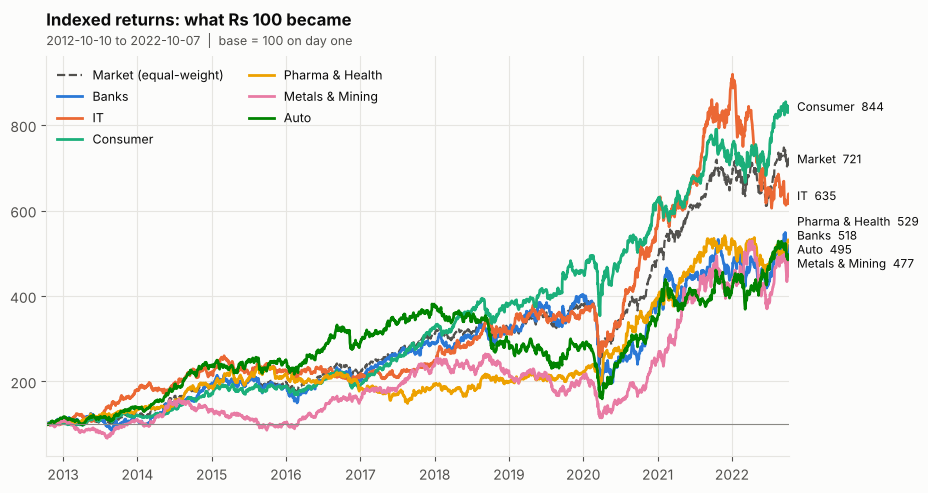

,Total return %,CAGR %,Ann. volatility %,Max drawdown %,Worst day %,Return / vol
Banks,417.74,17.89,25.62,-53.03,-18.07,0.70
IT,534.97,20.32,20.97,-34.10,-8.78,0.97
Consumer,743.68,23.80,17.19,-28.56,-11.80,1.38
Pharma & Health,429.22,18.15,19.95,-37.30,-8.45,0.91
Metals & Mining,376.61,16.92,29.53,-56.68,-11.80,0.57
Auto,395.03,17.36,22.60,-58.21,-12.93,0.77
Market (equal-weight),621.02,21.86,17.08,-38.33,-12.93,1.28


In [8]:
plot_returns("sector", ["Banks", "IT", "Consumer", "Pharma & Health", "Metals & Mining", "Auto"])

## 6. Drawdowns

A drawdown is the percentage below the previous high. It answers the question investors actually feel: *how far down was I, and how long did it take to get back?* The grey shaded area is the market proxy.

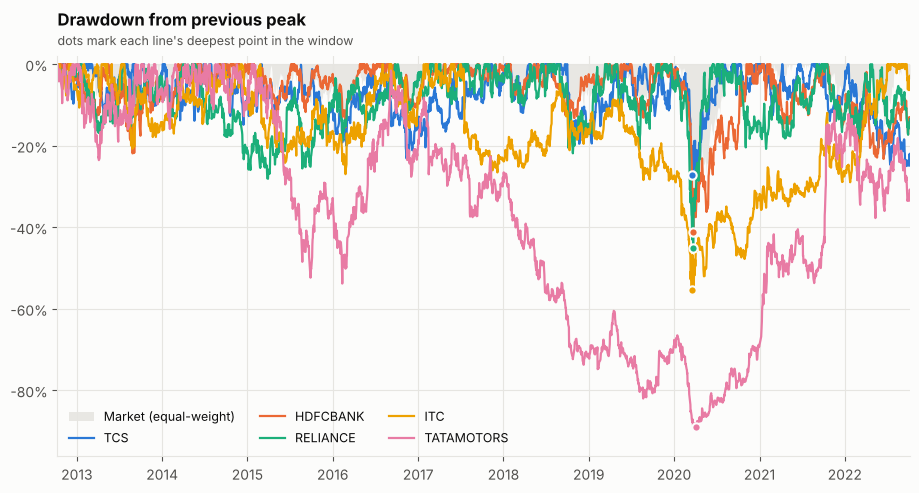

,Max drawdown %,Trough date,Longest time under water (trading days),Now vs peak %
TCS,-27.2,2020-03-19,347,-22.9
HDFCBANK,-41.1,2020-03-24,241,-14.3
RELIANCE,-45.1,2020-03-23,573,-13.5
ITC,-55.3,2020-03-16,1236,-3.6
TATAMOTORS,-89.1,2020-04-03,1900,-31.1


In [9]:
def plot_drawdowns(kind="stock", items=("TCS", "HDFCBANK", "RELIANCE", "ITC"), start=None, end=None):
    items = _cap(items)
    L = level(kind, items, start, end)
    D = drawdown(L) * 100
    DM = drawdown(MKT.loc[start:end]) * 100
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.fill_between(DM.index, DM, 0, color=GRID, alpha=0.9, label="Market (equal-weight)", lw=0)
    for i, c in enumerate(D.columns):
        ax.plot(D.index, D[c], color=SERIES[i], lw=1.6, label=c)
        t = D[c].idxmin()
        ax.scatter([t], [D[c].min()], s=36, color=SERIES[i], edgecolor=SURFACE, linewidth=1.5, zorder=5)
    ax.set_xlim(D.index[0], D.index[-1]); ax.set_ylim(min(D.min().min(), DM.min()) * 1.08, 2)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    _style(ax, "Drawdown from previous peak", "dots mark each line's deepest point in the window")
    ax.legend(loc="lower left", ncol=3, fontsize=9)
    plt.show()
    # underwater duration: longest stretch below a prior peak
    rows = {}
    for c in L.columns:
        s = L[c].dropna(); d = drawdown(s); under = d < 0
        grp = (~under).cumsum(); longest = under.groupby(grp).sum().max()
        rows[c] = {"Max drawdown %": round(d.min() * 100, 1), "Trough date": d.idxmin().date(),
                   "Longest time under water (trading days)": int(longest), "Now vs peak %": round(d.iloc[-1] * 100, 1)}
    display(pd.DataFrame(rows).T)

plot_drawdowns("stock", ["TCS", "HDFCBANK", "RELIANCE", "ITC", "TATAMOTORS"])

## 7. Volatility

Annualised volatility is the standard deviation of daily returns times √252, computed on a rolling window. Spikes mark the stress episodes; the *level* between spikes shows how risky a stock normally is.

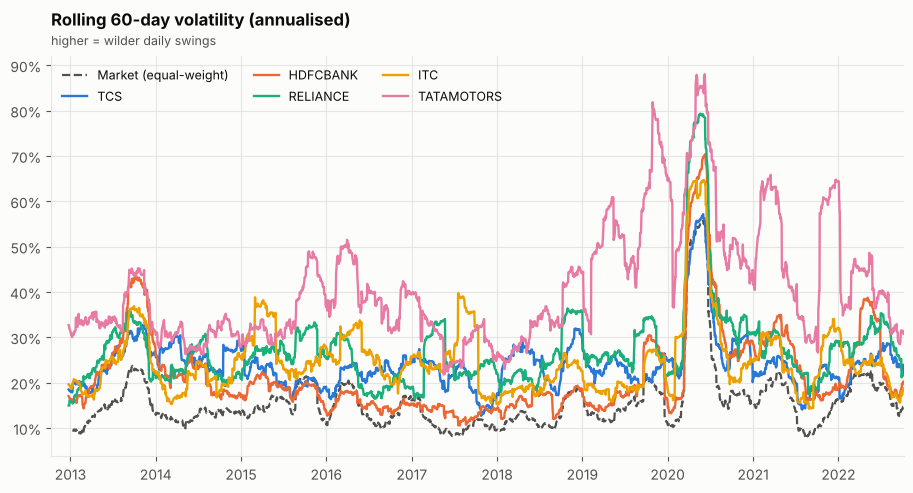

,Average vol %,Peak vol %,Peak date
TCS,24.1,57.2,2020-06-01
HDFCBANK,21.7,70.3,2020-06-09
RELIANCE,27.3,79.3,2020-05-20
ITC,24.9,64.7,2020-06-04
TATAMOTORS,40.7,88.0,2020-06-08


In [10]:
def plot_volatility(kind="stock", items=("TCS", "HDFCBANK", "RELIANCE", "ITC"), start=None, end=None, window=60):
    items = _cap(items)
    R = returns_of(kind, items, None, end)       # warm-up before `start` so the line begins full
    V = (R.rolling(window, min_periods=int(window * 0.8)).std() * np.sqrt(TDAYS) * 100).loc[start:end]
    VM = (mkt_ret.rolling(window).std() * np.sqrt(TDAYS) * 100).loc[start:end]
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.plot(VM.index, VM, color=MARKET_C, ls="--", lw=1.6, label="Market (equal-weight)")
    for i, c in enumerate(V.columns):
        ax.plot(V.index, V[c], color=SERIES[i], lw=1.7, label=c)
    ax.set_xlim(V.index[0], V.index[-1])
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    _style(ax, f"Rolling {window}-day volatility (annualised)", "higher = wilder daily swings")
    ax.legend(loc="upper left", ncol=3, fontsize=9)
    plt.show()
    avg = V.mean().round(1).rename("Average vol %").to_frame()
    avg["Peak vol %"] = V.max().round(1); avg["Peak date"] = V.idxmax().dt.date
    display(avg)

plot_volatility("stock", ["TCS", "HDFCBANK", "RELIANCE", "ITC", "TATAMOTORS"])

## 8. Correlation heatmap

Correlation of daily returns: 1 means two stocks move in lockstep, 0 means they are unrelated. Darker blue = more correlated. **Clustering** reorders the rows so that similar names sit together and groups appear as blocks. This matters because diversification only works across names that are *not* highly correlated.

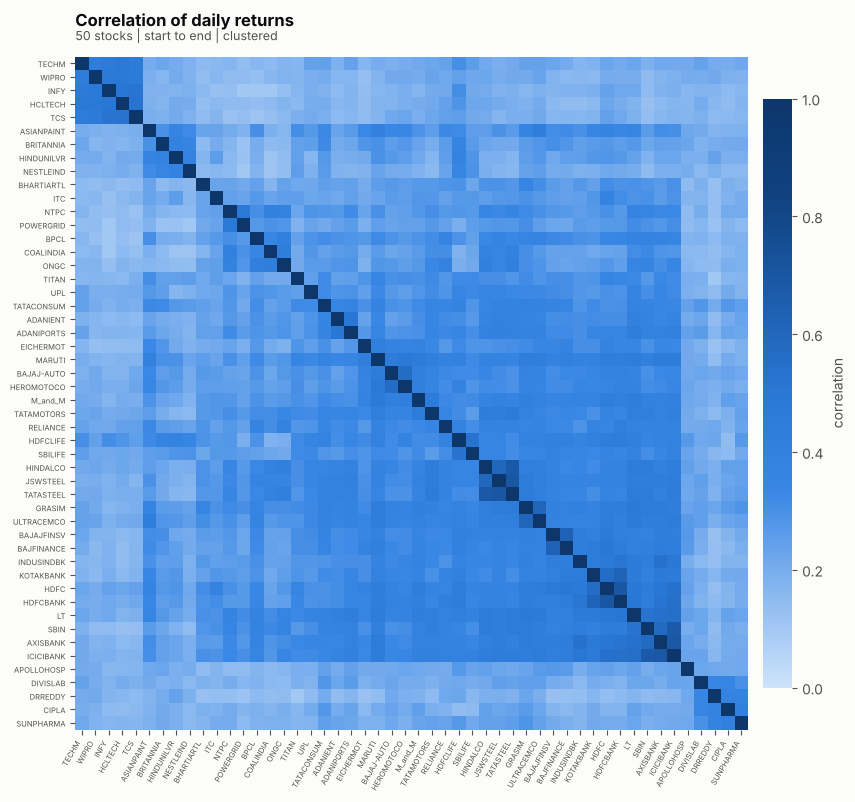

Average pairwise correlation: 0.28  (range 0.10 to 0.70)
Most correlated pairs:  HDFC / HDFCBANK (0.70), JSWSTEEL / TATASTEEL (0.70), AXISBANK / ICICIBANK (0.68)
Least correlated pairs: NESTLEIND / POWERGRID (0.10), INFY / COALINDIA (0.10), INFY / POWERGRID (0.10)


In [11]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

def corr_matrix(kind, items, start=None, end=None, cluster=True):
    C = returns_of(kind, items, start, end).corr(min_periods=60)
    if cluster and len(C) > 2:
        D = np.sqrt(np.clip(0.5 * (1 - C.fillna(0).values), 0, None)); np.fill_diagonal(D, 0)
        order = leaves_list(linkage(squareform(D, checks=False), "average"))
        C = C.iloc[order, order]
    return C

def draw_corr(ax, C, title, sub=None, annotate=None, vmin=0.0, vmax=1.0):
    n = len(C)
    annotate = (n <= 14) if annotate is None else annotate
    im = ax.imshow(C.values, cmap=SEQ, vmin=vmin, vmax=vmax, aspect="equal")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    fs = 8 if n <= 20 else 6.5 if n <= 35 else 5.5
    ax.set_xticklabels(C.columns, rotation=60, ha="right", fontsize=fs); ax.set_yticklabels(C.index, fontsize=fs)
    ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    if annotate:
        for i in range(n):
            for j in range(n):
                v = C.values[i, j]
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if v > 0.55 else INK)
    _style(ax, title, sub)
    return im

def plot_correlation(kind="stock", items=None, start=None, end=None, cluster=True):
    items = list(items) if items is not None else (SYMBOLS if kind == "stock" else list(SECTORS))
    C = corr_matrix(kind, items, start, end, cluster)
    n = len(C); size = 6.5 if n <= 14 else 9.5
    fig, ax = plt.subplots(figsize=(size, size * 0.92))
    im = draw_corr(ax, C, "Correlation of daily returns", f"{C.index.size} {kind}s | {start or 'start'} to {end or 'end'}" + (" | clustered" if cluster else ""))
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False); cb.set_label("correlation")
    plt.show()
    off = C.values[np.triu_indices(n, 1)]
    off = off[np.isfinite(off)]
    print(f"Average pairwise correlation: {off.mean():.2f}  (range {off.min():.2f} to {off.max():.2f})")
    iu = np.triu_indices(n, 1); pairs = pd.Series(C.values[iu], index=[f"{C.index[i]} / {C.columns[j]}" for i, j in zip(*iu)]).dropna().sort_values()
    print("Most correlated pairs: ", ", ".join(f"{k} ({v:.2f})" for k, v in pairs.tail(3)[::-1].items()))
    print("Least correlated pairs:", ", ".join(f"{k} ({v:.2f})" for k, v in pairs.head(3).items()))

plot_correlation("stock", SYMBOLS)

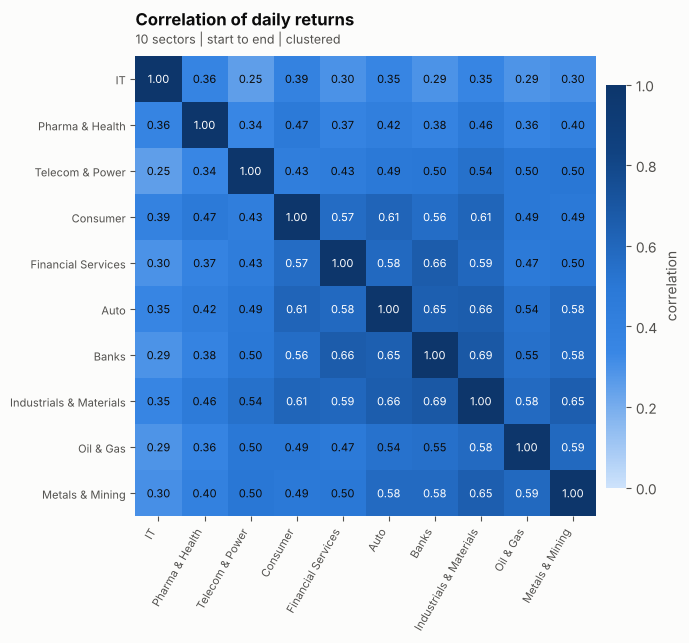

Average pairwise correlation: 0.48  (range 0.25 to 0.69)
Most correlated pairs:  Banks / Industrials & Materials (0.69), Financial Services / Banks (0.66), Auto / Industrials & Materials (0.66)
Least correlated pairs: IT / Telecom & Power (0.25), IT / Oil & Gas (0.29), IT / Banks (0.29)


In [12]:
plot_correlation("sector", list(SECTORS))

## 9. Finding the crashes

Rather than hand-picking dates, the notebook **detects** crashes from the data: each time the market proxy sets a new high it starts a new episode, and the episode's trough is its lowest point. Episodes deeper than 10% are kept. The event names are attached afterwards by matching the trough date to well-known stress periods, so treat them as labels, not causal claims.

In [13]:
EVENT_LABELS = [  # (label, window that the trough date must fall in)
    ("Taper tantrum", "2013-06-01", "2013-09-30"),
    ("Demonetisation", "2016-11-01", "2017-01-31"),
    ("China / oil sell-off", "2015-08-01", "2016-03-31"),
    ("IL&FS / NBFC stress", "2018-09-01", "2018-11-30"),
    ("COVID-19 crash", "2020-02-15", "2020-04-30"),
    ("Rate-hike / Ukraine sell-off", "2022-01-01", "2022-08-31"),
]

def find_crashes(min_depth=-0.10, top=6):
    L = MKT
    peak_id = (L == L.cummax()).cumsum()
    rows = []
    for pid, g in L.groupby(peak_id):
        dd = g / g.iloc[0] - 1
        if dd.min() <= min_depth:
            trough = dd.idxmin()
            nxt = L.index[L.index.get_loc(g.index[-1]) + 1] if g.index[-1] != L.index[-1] else None
            label = next((n for n, a, b in EVENT_LABELS if pd.Timestamp(a) <= trough <= pd.Timestamp(b)), "Drawdown")
            rows.append({"Crash": label, "Peak": g.index[0], "Trough": trough, "Market drop %": dd.min() * 100,
                         "Days peak to trough": int(L.index.get_loc(trough) - L.index.get_loc(g.index[0])),
                         "Days to new high": (int(L.index.get_loc(nxt) - L.index.get_loc(trough)) if nxt is not None else None),
                         "Recovered": nxt is not None})
    df = pd.DataFrame(rows).sort_values("Market drop %").head(top).sort_values("Peak").reset_index(drop=True)
    df.index = df.index + 1; df.index.name = "#"
    return df

CRASHES = find_crashes()
disp = CRASHES.copy(); disp["Peak"] = disp["Peak"].dt.date; disp["Trough"] = disp["Trough"].dt.date; disp["Market drop %"] = disp["Market drop %"].round(1)
display(disp)

,Crash,Peak,Trough,Market drop %,Days peak to trough,Days to new high,Recovered
#,,,,,,,
1,Taper tantrum,2013-05-17,2013-08-28,-11.9,71,15,True
2,China / oil sell-off,2015-08-06,2016-02-12,-16.4,127,73,True
3,Demonetisation,2016-09-08,2016-12-26,-12.1,72,29,True
4,IL&FS / NBFC stress,2018-08-31,2018-10-26,-13.4,36,114,True
5,COVID-19 crash,2020-01-17,2020-03-23,-38.3,44,105,True
6,Rate-hike / Ukraine sell-off,2021-10-18,2022-06-20,-15.1,167,37,True


## 10. Crash comparison

Pick a crash and see how each sector (or stock) behaved from the market's peak. Everything is indexed to 100 **on the peak date** and aligned by trading days since the peak, so different crashes can be compared on the same footing. The vertical line marks the market's trough.

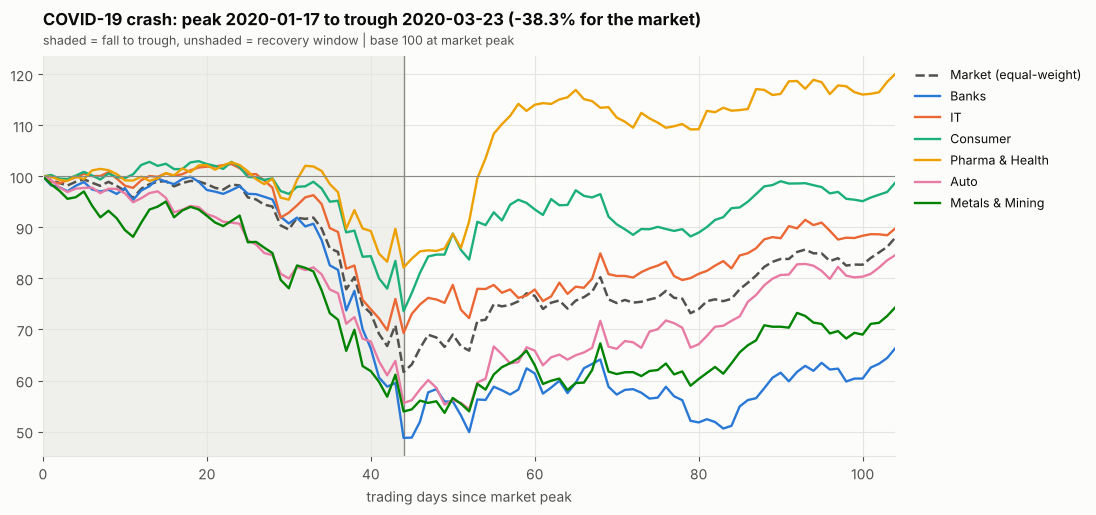

,Peak to trough %,Trough +60d vs peak %
Pharma & Health,-17.9,20.1
Consumer,-26.4,-1.2
IT,-30.7,-10.2
Market,-38.3,-12.0
Auto,-44.4,-15.4
Metals & Mining,-46.1,-25.6
Banks,-51.3,-33.6


In [14]:
def _crash_row(crash):
    if isinstance(crash, (int, np.integer)):
        return CRASHES.loc[crash]
    return CRASHES[CRASHES["Crash"].str.contains(crash, case=False)].iloc[0]

def plot_crash(crash=1, kind="sector", items=None, after=60):
    row = _crash_row(crash)
    items = list(items) if items is not None else (["Banks", "IT", "Consumer", "Pharma & Health", "Auto", "Metals & Mining"] if kind == "sector" else ["TCS", "HDFCBANK", "RELIANCE", "ITC", "TATAMOTORS"])
    items = _cap(items)
    p, t = row["Peak"], row["Trough"]
    i0, i1 = MKT.index.get_loc(p), MKT.index.get_loc(t)
    end = MKT.index[min(i1 + after, len(MKT) - 1)]
    L = level(kind, items).loc[p:end]
    L = L / L.iloc[0] * 100                      # base 100 at the market peak
    M = MKT.loc[p:end] / MKT.loc[p] * 100
    x = np.arange(len(L))
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.axvspan(0, i1 - i0, color=GRID, alpha=0.55, lw=0)
    ax.axvline(i1 - i0, color=MUTED, lw=1)
    ax.plot(x, M.values, color=MARKET_C, ls="--", lw=1.8, label="Market (equal-weight)")
    for i, c in enumerate(L.columns):
        ax.plot(x, L[c].values, color=SERIES[i], lw=1.7, label=c)
    ax.axhline(100, color=MUTED, lw=0.8)
    ax.set_xlim(0, len(L) - 1); ax.set_xlabel("trading days since market peak")
    _style(ax, f"{row['Crash']}: peak {p.date()} to trough {t.date()} ({row['Market drop %']:.1f}% for the market)",
           "shaded = fall to trough, unshaded = recovery window | base 100 at market peak")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
    plt.show()
    tr = (L.iloc[i1 - i0] / 100 - 1) * 100
    end_r = (L.iloc[-1] / 100 - 1) * 100
    out = pd.DataFrame({"Peak to trough %": tr, f"Trough +{after}d vs peak %": end_r}).round(1)
    out.loc["Market"] = [round(M.iloc[i1 - i0] - 100, 1), round(M.iloc[-1] - 100, 1)]
    display(out.sort_values("Peak to trough %", ascending=False))

plot_crash(5, "sector")

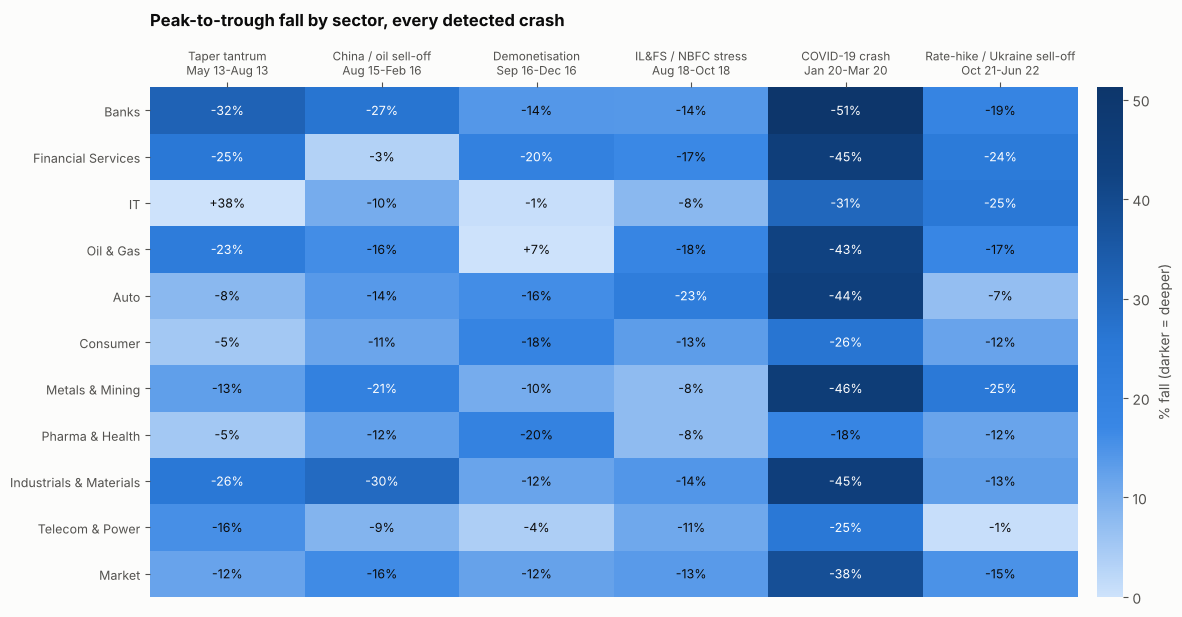

In [15]:
def crash_heatmap(kind="sector", items=None):
    # Trough depth of every sector (or stock) in every detected crash, one grid.
    items = list(items) if items is not None else (list(SECTORS) if kind == "sector" else SYMBOLS)
    L = level(kind, items)
    cols = {}
    for k, row in CRASHES.iterrows():
        seg = L.loc[row["Peak"]:row["Trough"]]
        cols[f"{row['Crash']}\n{row['Peak'].strftime('%b %y')}-{row['Trough'].strftime('%b %y')}"] = (seg.iloc[-1] / seg.iloc[0] - 1) * 100
    G = pd.DataFrame(cols)
    G.loc["Market"] = [row["Market drop %"] for _, row in CRASHES.iterrows()]
    G = G.loc[G.drop(index="Market").mean(axis=1).sort_values().index.tolist() + ["Market"]] if kind == "stock" else G
    fig, ax = plt.subplots(figsize=(max(8, 1.6 * G.shape[1] + 3), max(4.5, 0.42 * len(G) + 2)))
    depth = (-G).clip(lower=0)                    # deeper fall = darker
    im = ax.imshow(depth.values, cmap=SEQ, aspect="auto", vmin=0, vmax=max(40, np.nanmax(depth.values)))
    ax.set_xticks(range(G.shape[1])); ax.set_xticklabels(G.columns, fontsize=8.5)
    ax.set_yticks(range(len(G))); ax.set_yticklabels(G.index, fontsize=9 if len(G) < 25 else 6.5)
    ax.xaxis.tick_top(); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    for i in range(G.shape[0]):
        for j in range(G.shape[1]):
            v = G.values[i, j]
            if np.isfinite(v) and len(G) < 25:
                ax.text(j, i, f"{v:+.0f}%", ha="center", va="center", fontsize=9, color="#ffffff" if depth.values[i, j] > 20 else INK)
    ax.set_title(f"Peak-to-trough fall by {kind}, every detected crash", loc="left", pad=44)
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.outline.set_visible(False); cb.set_label("% fall (darker = deeper)")
    plt.show()
    return G

G_sector = crash_heatmap("sector")

In [16]:
def crash_leaders(crash=1, n=5):
    row = _crash_row(crash)
    seg = px.loc[row["Peak"]:row["Trough"]]
    r = (seg.apply(lambda c: c.dropna().iloc[-1] / c.dropna().iloc[0] - 1 if c.dropna().size > 1 else np.nan) * 100).dropna().sort_values()
    best = r.tail(n)[::-1].round(1).rename("% change"); worst = r.head(n).round(1).rename("% change")
    print(f"{row['Crash']}  |  market {row['Market drop %']:.1f}%  |  {len(r)} stocks with data")
    display(pd.concat({"Held up best": best.to_frame().assign(Sector=[STOCK_SECTOR[s] for s in best.index]),
                       "Fell the most": worst.to_frame().assign(Sector=[STOCK_SECTOR[s] for s in worst.index])}))

for k in CRASHES.index:
    crash_leaders(k)

Taper tantrum  |  market -11.9%  |  48 stocks with data


% change                   Sector
Held up best  TECHM          47.7                       IT
              WIPRO          39.0                       IT
              HCLTECH        36.1                       IT
              INFY           34.0                       IT
              TCS            30.9                       IT
Fell the most AXISBANK      -44.6                    Banks
              SBIN          -37.0                    Banks
              BPCL          -36.2                Oil & Gas
              ADANIENT      -34.5  Industrials & Materials
              ICICIBANK     -34.2                    Banks

China / oil sell-off  |  market -16.4%  |  48 stocks with data


% change                   Sector
Held up best  JSWSTEEL        11.4          Metals & Mining
              BAJFINANCE       9.8       Financial Services
              TITAN            8.6                 Consumer
              INFY             0.7                       IT
              SUNPHARMA        0.6          Pharma & Health
Fell the most ADANIPORTS     -48.7  Industrials & Materials
              SBIN           -46.4                    Banks
              HINDALCO       -43.2          Metals & Mining
              LT             -41.9  Industrials & Materials
              ICICIBANK      -37.8                    Banks

Demonetisation  |  market -12.1%  |  48 stocks with data


% change              Sector
Held up best  ONGC            17.0           Oil & Gas
              HCLTECH          2.9                  IT
              BPCL             2.6           Oil & Gas
              RELIANCE         1.4           Oil & Gas
              TECHM            1.0                  IT
Fell the most DIVISLAB       -42.8     Pharma & Health
              AXISBANK       -31.4               Banks
              BAJFINANCE     -30.3  Financial Services
              TITAN          -28.9            Consumer
              ASIANPAINT     -26.4            Consumer

... (2 outputs left out)

COVID-19 crash  |  market -38.3%  |  50 stocks with data


% change                   Sector
Held up best  DIVISLAB        -2.0          Pharma & Health
              DRREDDY         -8.8          Pharma & Health
              HINDUNILVR      -9.3                 Consumer
              NESTLEIND      -16.2                 Consumer
              ASIANPAINT     -17.8                 Consumer
Fell the most INDUSINDBK     -75.1                    Banks
              TATAMOTORS     -66.4                     Auto
              AXISBANK       -58.3                    Banks
              HINDALCO       -58.2          Metals & Mining
              UPL            -56.8  Industrials & Materials

Rate-hike / Ukraine sell-off  |  market -15.1%  |  50 stocks with data


% change                   Sector
Held up best  ADANIENT        28.7  Industrials & Materials
              M_and_M          7.9                     Auto
              POWERGRID        6.6          Telecom & Power
              ITC              5.3                 Consumer
              COALINDIA        4.3          Metals & Mining
Fell the most WIPRO          -41.0                       IT
              HINDALCO       -40.8          Metals & Mining
              BAJAJFINSV     -37.3       Financial Services
              INDUSINDBK     -35.7                    Banks
              TATASTEEL      -35.7          Metals & Mining

### Does diversification survive a crash?

If diversification works, stocks should be only loosely correlated. The chart below tracks the **average pairwise correlation across all 50 stocks** (60-day window) with the detected crashes shaded. Correlations typically jump exactly when you need independence most.

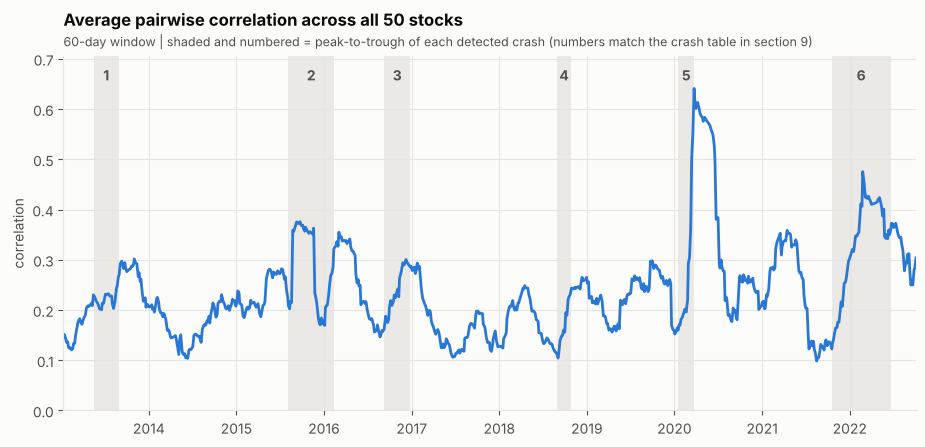

Average correlation inside crash windows: 0.28   outside: 0.23
Peak: 0.64 on 2020-03-23


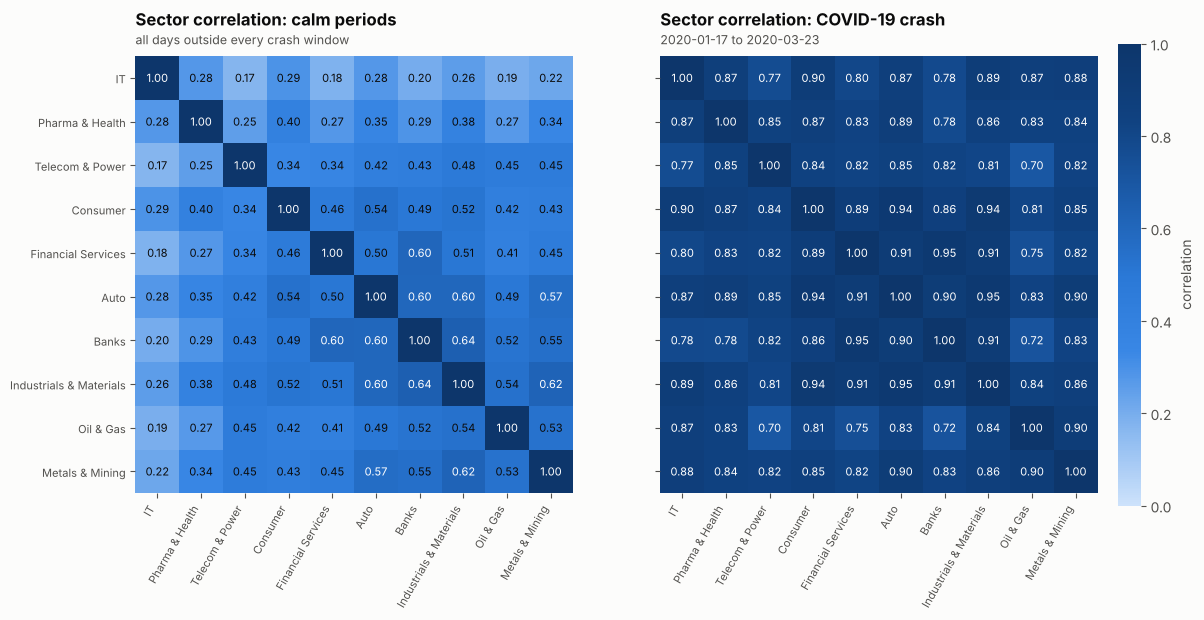

In [17]:
def rolling_avg_corr(window=60, step=3):
    idx = ret.index[window::step]; vals = []
    for d in idx:
        w = ret.loc[:d].iloc[-window:]
        w = w.loc[:, w.notna().sum() >= int(window * 0.8)]
        C = w.corr().values; n = C.shape[0]
        vals.append(np.nanmean(C[np.triu_indices(n, 1)]))
    return pd.Series(vals, index=idx)

AC = rolling_avg_corr()
fig, ax = plt.subplots(figsize=(11, 4.6))
for k, row in CRASHES.iterrows():
    ax.axvspan(row["Peak"], row["Trough"], color=GRID, alpha=0.8, lw=0)
    mid = row["Peak"] + (row["Trough"] - row["Peak"]) / 2
    ax.text(mid, 0.97, str(k), fontsize=10, fontweight="bold", color=INK2, va="top", ha="center", transform=ax.get_xaxis_transform())
ax.plot(AC.index, AC.values, color=SERIES[0], lw=2)
ax.set_ylim(0, max(0.7, AC.max() * 1.1)); ax.set_xlim(AC.index[0], AC.index[-1])
_style(ax, "Average pairwise correlation across all 50 stocks", "60-day window | shaded and numbered = peak-to-trough of each detected crash (numbers match the crash table in section 9)", "correlation")
plt.show()

inside = pd.Series(False, index=AC.index)
for _, row in CRASHES.iterrows():
    inside |= (AC.index >= row["Peak"]) & (AC.index <= row["Trough"])
print(f"Average correlation inside crash windows: {AC[inside].mean():.2f}   outside: {AC[~inside].mean():.2f}")
print(f"Peak: {AC.max():.2f} on {AC.idxmax().date()}")

# side-by-side heatmaps: calm vs the worst crash
worst = CRASHES["Market drop %"].idxmin(); wrow = CRASHES.loc[worst]
Cc = corr_matrix("sector", list(SECTORS), start=None, end=None, cluster=True)
order = list(Cc.index)
calm_mask = ~pd.Series(False, index=ret.index)
for _, row in CRASHES.iterrows():
    calm_mask &= ~((ret.index >= row["Peak"]) & (ret.index <= row["Trough"]))
C_calm = returns_of("sector", order).loc[calm_mask].corr().loc[order, order]
C_cr = returns_of("sector", order, wrow["Peak"], wrow["Trough"]).corr().loc[order, order]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
draw_corr(axes[0], C_calm, "Sector correlation: calm periods", "all days outside every crash window", vmin=0, vmax=1)
im = draw_corr(axes[1], C_cr, f"Sector correlation: {wrow['Crash']}", f"{wrow['Peak'].date()} to {wrow['Trough'].date()}", vmin=0, vmax=1)
axes[1].set_yticklabels([])        # same row order as the left panel
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02); cb.outline.set_visible(False); cb.set_label("correlation")
plt.show()

## 11. The interactive dashboard

Pick stocks and sectors, a date range and a crash, and every chart above redraws. It needs `ipywidgets`, which is preinstalled in Colab and installed with Jupyter (`pip install ipywidgets` otherwise). If it is missing the cell prints a note and shows the default view instead, which is what you see in the saved output of this file.

- **Stocks**: hold Ctrl/Cmd to select several (max 8 are drawn per chart).
- **Sectors**: choosing sectors in the sector list filters the stock list to their members.
- **View by**: switch every tab between your stock selection and your sector selection.

ipywidgets is not installed in this environment, so the controls cannot be shown here.
Install it with `pip install ipywidgets`, restart, and re-run this cell to get the live dashboard.
Showing the default view of the Indexed returns tab instead:


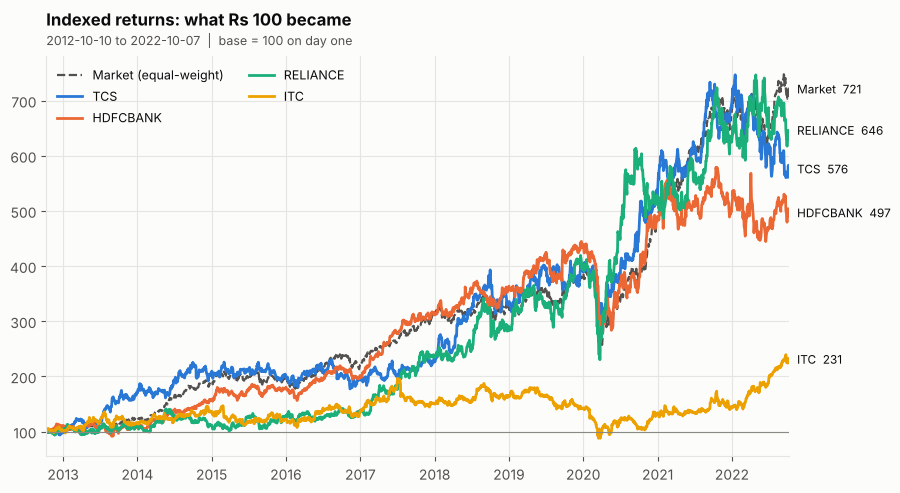

,Total return %,CAGR %,Ann. volatility %,Max drawdown %,Worst day %,Return / vol
TCS,476.04,19.16,24.69,-27.21,-9.41,0.78
HDFCBANK,396.50,17.40,23.72,-41.05,-12.61,0.73
RELIANCE,546.06,20.53,28.59,-45.09,-13.15,0.72
ITC,130.89,8.74,26.10,-55.35,-12.81,0.33
Market (equal-weight),621.02,21.86,17.08,-38.33,-12.93,1.28


In [18]:
def dashboard():
    try:
        import ipywidgets as w
    except ImportError:
        print("ipywidgets is not installed in this environment, so the controls cannot be shown here.")
        print("Install it with `pip install ipywidgets`, restart, and re-run this cell to get the live dashboard.")
        print("Showing the default view of the Indexed returns tab instead:")
        plot_returns("stock", ["TCS", "HDFCBANK", "RELIANCE", "ITC"])
        return None

    dates = list(px.index.strftime("%Y-%m-%d"))
    sel_sector = w.SelectMultiple(options=list(SECTORS), value=("Banks", "IT", "Consumer"), rows=10, description="Sectors", layout=w.Layout(width="260px"))
    sel_stock = w.SelectMultiple(options=SYMBOLS, value=("TCS", "HDFCBANK", "RELIANCE", "ITC"), rows=10, description="Stocks", layout=w.Layout(width="260px"))
    rng = w.SelectionRangeSlider(options=dates, index=(0, len(dates) - 1), description="Dates", layout=w.Layout(width="95%"))
    view = w.ToggleButtons(options=[("Stocks", "stock"), ("Sectors", "sector")], value="stock", description="View by")
    win = w.IntSlider(value=60, min=20, max=250, step=10, description="Vol window")
    log = w.Checkbox(value=False, description="Log scale")
    clus = w.Checkbox(value=True, description="Cluster heatmap")
    crash = w.Dropdown(options=[(f"{r['Crash']}  ({r['Market drop %']:.0f}%)", k) for k, r in CRASHES.iterrows()], description="Crash")

    def narrow_stocks(change):
        sectors = change["new"]
        if sectors:
            keep = [s for s in SYMBOLS if STOCK_SECTOR[s] in sectors]
            sel_stock.options = keep
            sel_stock.value = tuple(keep[:4])
        else:
            sel_stock.options = SYMBOLS
    sel_sector.observe(narrow_stocks, names="value")

    def chosen(kind):
        return list(sel_stock.value) if kind == "stock" else list(sel_sector.value)

    outs = {n: w.Output() for n in ["Returns", "Drawdowns", "Volatility", "Correlation", "Crash"]}
    tabs = w.Tab(children=list(outs.values()))
    for i, n in enumerate(outs): tabs.set_title(i, n)

    def redraw(*_):
        a, b = rng.value; k = view.value; items = chosen(k)
        for o in outs.values(): o.clear_output(wait=True)
        if not items:
            with outs["Returns"]: print("Pick at least one item.")
            return
        with outs["Returns"]: plot_returns(k, items, a, b, log.value)
        with outs["Drawdowns"]: plot_drawdowns(k, items, a, b)
        with outs["Volatility"]: plot_volatility(k, items, a, b, win.value)
        with outs["Correlation"]:
            if len(items) < 2: print("Pick at least two items for a correlation heatmap.")
            else: plot_correlation(k, items, a, b, clus.value)
        with outs["Crash"]: plot_crash(crash.value, k, items)

    for ctl in (sel_sector, sel_stock, rng, view, win, log, clus, crash):
        ctl.observe(redraw, names="value")
    ui = w.VBox([w.HBox([sel_sector, sel_stock, w.VBox([view, win, log, clus, crash])]), rng, tabs])
    display(ui)
    redraw()
    return ui

_ui = dashboard()

## 12. Plain-language takeaways

These come from the outputs above; the crash labels are matched by date and are not causal claims.

1. **One crash dwarfs the rest.** Five of the six detected episodes were 12% to 16% falls for the equal-weight market. COVID-19 was 38.3% in just 44 trading days. The market regained its previous high 15 to 114 trading days after each trough.
2. **There is no permanent safe haven.** The best sector in each crash was different: IT (Taper tantrum, +38%), Financial Services (China / oil sell-off, -3%), Oil & Gas (Demonetisation, +7%), Metals & Mining (IL&FS / NBFC stress, -8%), Pharma & Health (COVID-19, -18%) and Telecom & Power (Rate-hike / Ukraine, -1%). Last crash's winner was not a reliable guide to the next.
3. **Banks were the repeat offender.** They were the worst sector in the Taper tantrum (-32%) and in COVID-19 (-51%), and among the worst in the China / oil sell-off (-27%). Within the sector, IndusInd Bank fell 75% in the COVID crash while Divi's Labs fell 2%, so stock choice mattered as much as sector choice.
4. **Diversification weakens exactly when it is needed.** The average correlation between sectors was 0.41 in calm periods but 0.85 during the COVID-19 crash. Across all 50 stocks the average pairwise correlation peaked at 0.64 on 23 Mar 2020. In the other crashes the rise was more modest: 0.28 on average inside crash windows against 0.23 outside.
5. **Diversification still cuts day-to-day risk.** The median single stock had ~30% annualised volatility; the equal-weight market proxy had ~17%.

*Reminder: the market line is an equal-weight proxy, only today's constituents are included, and the data stops in October 2022.*

## Method notes and limits

- **Returns** are daily simple returns of adjusted close (splits and dividends included). Across data gaps the return is left missing rather than interpolated.
- **Sector and market lines** are equal-weight and rebalanced daily, which is not how a cap-weighted index or a real portfolio behaves, and daily rebalancing is a modelling convenience.
- **Volatility** is the sample standard deviation of daily returns times √252. **Drawdown** is measured on adjusted prices, so dividends are treated as reinvested.
- **Crash detection** uses the equal-weight proxy, so a crash that hit mainly large caps could look milder here than in the headline NIFTY 50.
- **Survivorship bias**: only today's 50 constituents are included, so past weakness is understated.
- **Not investment advice.** This is a historical exploration tool.

**Re-running on fresh data:** replace the embedded `BLOB` cell with a loader that builds `adj`, `close` and `volume` DataFrames (dates as index, tickers as columns), for example with `yfinance.download([t + ".NS" for t in tickers])`. Everything below it works unchanged.